# Read a flotation bank as a kinetic response

**Question:** How do particle-class batch rates and a continuous cell-bank residence model yield different recovery measures?

Level: 1. Prerequisites: None; begin here. Reading time: 18 minutes.

## Objectives

Run the Cu-Mo rougher and distinguish its virtual batch curve from the continuously fed bank response. Understand why recovery versus time is a process response, not a decorative animation.

## Setup

```bash
pip install numpy==2.2.6 scipy==1.17.1 pandas==2.2.3 matplotlib==3.11.2 nbclient==0.11.0 nbformat==5.11.1 ipykernel==7.4.0 SALib==1.6.0
```

The OreFlow pipeline is imported from `data-pipeline/`; this notebook never installs packages.

For the level 1 02-flotation lesson, record the pinned versions before analysis so the environment behind its tables and figures can be reconstructed.

In [1]:
# Import analysis tools and record their exact versions.
import importlib.metadata
import json
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Resolve the local pipeline from the repository-relative layout.
repo = Path("../../../").resolve()
sys.path.insert(0, str(repo / "data-pipeline"))
for package in ("numpy", "scipy", "pandas", "matplotlib", "nbclient", "nbformat", "ipykernel"):
    print(package, importlib.metadata.version(package))


numpy 2.2.6
scipy 1.17.1
pandas 2.2.3
matplotlib 3.11.2
nbclient 0.11.0
nbformat 5.11.1
ipykernel 7.4.0


## Data

Owner: OreFlow authors; authored Cu-Mo scenario in `data/derived/cases/copper_molybdenum.json`, MIT project licence. The kinetic curve is generated by the engine, not measured in a laboratory or plant. Repository: https://github.com/fsantibanezleal/CAOS_OreFlow.

## Method

OreFlow aggregates class-specific rates as $R_b(t)=\sum_j c_jx_j(1-e^{-k_jt})/\sum_j c_jx_j$. A continuous bank has a different residence-time distribution and is calculated separately. Call `simulate` and the production `trace` builder.

Select one authored Cu-Mo case and run the same circuit and trace methods used by OreFlow's data pipeline.

In [2]:
from pipeline.cases.catalog import CASES
from pipeline.engine.circuit import simulate
from pipeline.engine.trace import trace

# Solve the rougher and serialize its kinetic record with the production trace builder.
case = next(item for item in CASES if item.id == "copper_molybdenum")
result = simulate(case.ore, case.plant, case.nominal)
record = trace(result, case.nominal, case.plant.family)
kinetics = record["methods"]["kinetics"]
print("family:", record["family"], "| status:", kinetics["status"])
print("bank residence (min):", round(kinetics["bank"]["residence_min"], 2))
print("engine rougher recovery (%):", round(kinetics["bank"]["engine_rougher_pct"], 2))


family: rougher | status: computed
bank residence (min): 29.16
engine rougher recovery (%): 94.01


Plot batch recovery against time and continuous-bank recovery against cell position; the x-axes represent different residence models.

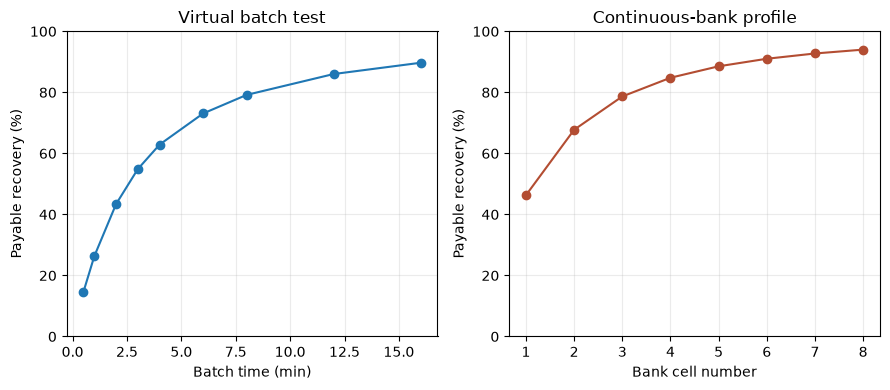

In [3]:
# Plot batch recovery against time and continuous-bank recovery against cell position; the x-axes
# represent different residence models.
bank = record["curves"]["bank_profile"]
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
axes[0].plot(kinetics["times_min"], kinetics["batch_recovery_pct"], "o-", label="Virtual batch")
axes[0].set(xlabel="Batch time (min)", ylabel="Payable recovery (%)", title="Virtual batch test")
axes[1].plot([v["cell"] for v in bank], [100 * v["recovery"] for v in bank], "o-", color="#b34d32")
axes[1].set(
    xlabel="Bank cell number", ylabel="Payable recovery (%)", title="Continuous-bank profile"
)
for ax in axes:
    ax.set_ylim(0, 100)
    ax.grid(True, alpha=0.25)
fig.tight_layout()


Figure 11 in the level 1 02 flotation lesson reports outputs of independently solved operating points. For figure 11 in level 1 02 flotation, each mark is a separate model evaluation at its stated setting. For figure 11 in level 1 02 flotation, check recovery, size and energy against the contract limits. The line in figure 11 only guides comparison.

Read rougher feed, concentrate and tailings together. Grade and recovery answer different questions.

In [4]:
# Read rougher feed, concentrate and tailings together.
streams = record["streams"]
rows = [
    (name, streams[name]["solids_tph"], streams[name]["grades"][kinetics["species"]])
    for name in ("rougher_feed", "rougher_concentrate", "rougher_tail")
    if name in streams
]
display(pd.DataFrame(rows, columns=["Stream", "Solids (t/h)", f"{kinetics['species']} grade (%)"]))


,Stream,Solids (t/h),Cu grade (%)
0,rougher_feed,687.297218,0.620996
1,rougher_concentrate,61.023570,6.574911
2,rougher_tail,626.273648,0.040852


In the level 1 02 flotation case, the 0.9× nominal throughput run changes fresh-feed rate while holding the other controls at their authored nominal point. For the level 1 02 flotation case at 0.9× feed, recovery, product size and energy are coupled outputs of the resolved circuit model.

In [5]:
# Re-solve the production circuit at one controlled throughput multiplier.
from pipeline.cases.catalog import CASES
from pipeline.engine.circuit import simulate

case = next(item for item in CASES if item.id == "copper_molybdenum")
factor = 0.9
point_0_9 = case.nominal.with_values(throughput_tph=case.nominal.throughput_tph * factor)
response_0_9 = simulate(case.ore, case.plant, point_0_9)
print("throughput (t/h):", round(point_0_9.throughput_tph, 2))
print("recovery (%):", round(response_0_9.metrics["recovery_pct"], 3))
print("product P80 (µm):", round(response_0_9.metrics["p80_um"], 2))


throughput (t/h): 576.0
recovery (%): 94.143
product P80 (µm): 150.0


In the level 1 02 flotation case, the 1.1× nominal throughput run changes fresh-feed rate while holding the other controls at their authored nominal point. For the level 1 02 flotation case at 1.1× feed, recovery, product size and energy are coupled outputs of the resolved circuit model.

In [6]:
# Re-solve the production circuit at one controlled throughput multiplier.
from pipeline.cases.catalog import CASES
from pipeline.engine.circuit import simulate

case = next(item for item in CASES if item.id == "copper_molybdenum")
factor = 1.1
point_1_1 = case.nominal.with_values(throughput_tph=case.nominal.throughput_tph * factor)
response_1_1 = simulate(case.ore, case.plant, point_1_1)
print("throughput (t/h):", round(point_1_1.throughput_tph, 2))
print("recovery (%):", round(response_1_1.metrics["recovery_pct"], 3))
print("product P80 (µm):", round(response_1_1.metrics["p80_um"], 2))


throughput (t/h): 704.0
recovery (%): 92.753
product P80 (µm): 150.0


In the level 1 02 flotation lesson, plot reading 1 considers in this level 1 02 flotation plot, compare recovery with product P80 across the controlled throughput changes. In the level 1 02 flotation lesson, plot reading 2 considers the two axes keep unlike units separate, so interpret each change as a response of this authored case rather than as an empirical plant trend. In the level 1 02 flotation lesson, plot reading 3 considers the nominal point is included as a reference for the neighboring settings. In the level 1 02 flotation lesson, plot reading 4 considers for read a flotation bank as a kinetic response, the plotted points come from separate engine evaluations, and the lines only guide the eye between tested settings.

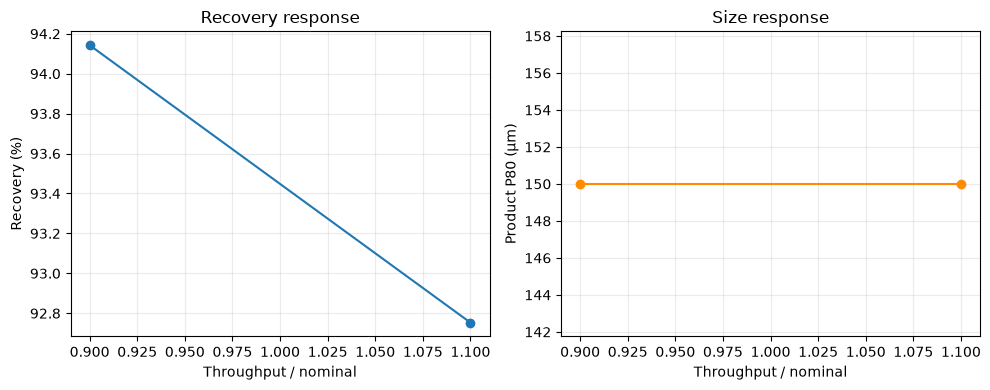

In [7]:
# Plot responses from the independently solved operating points.
import matplotlib.pyplot as plt

factors = [0.9, 1.1]
runs = [response_0_9, response_1_1]
rates = [run.metrics["recovery_pct"] for run in runs]
sizes = [run.metrics["p80_um"] for run in runs]
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(factors, rates, marker="o")
axes[0].set(xlabel="Throughput / nominal", ylabel="Recovery (%)", title="Recovery response")
axes[1].plot(factors, sizes, marker="o", color="darkorange")
axes[1].set(xlabel="Throughput / nominal", ylabel="Product P80 (µm)", title="Size response")
for axis in axes:
    axis.grid(True, alpha=0.25)
fig.tight_layout()


Figure 19 in the level 1 02 flotation lesson reports outputs of independently solved operating points. For figure 19 in level 1 02 flotation, each mark is a separate model evaluation at its stated setting. For figure 19 in level 1 02 flotation, check recovery, size and energy against the contract limits. The line in figure 19 only guides comparison.

At level 1 in 02 flotation, interpretation 1 is that flotation recovery is conditional on the solids and mineral distribution delivered by grinding, the declared floatability parameters, collector response and available residence time. At level 1 in 02 flotation, interpretation 2 is that a higher feed rate changes the time available per unit mass even when cell volume is unchanged. At level 1 in 02 flotation, interpretation 3 is that the model represents that coupling through the bank calculation. At level 1 in 02 flotation, interpretation 4 is that it does not animate individual particles or infer froth behaviour from an image. At level 1 in 02 flotation, interpretation 5 is that compare valuable-mineral recovery with concentrate grade and water recovery, because a recovery increase can also carry more gangue or water. At level 1 in 02 flotation, interpretation 6 is that kinetic forms such as first-order, fast/slow and distributed-rate models can fit similar batch curves while giving different bank projections. At level 1 in 02 flotation, interpretation 7 is that a synthetic exact-rate reference allows internal approximation error to be measured, but it is not a laboratory test. At level 1 in 02 flotation, interpretation 8 is that transfer to a plant requires timed samples, reagent records, air rate, cell geometry and an independently held-out campaign.

## Results

**Answer:** In this level 1 02 flotation lesson, the executed circuit reports recovery of 94.01 percent at the first controlled throughput setting for Read a flotation bank as a kinetic response.

The batch curve is a virtual test generated from OreFlow's own class-rate distribution; the bank profile applies a continuous residence model. Their difference is not plant evidence. Concentrate grade and recovery describe separate outcomes.

## Summary

You ran OreFlow's solver and inspected its simulated batch and bank responses. The record is not laboratory data, and a visual step through the circuit is not physical plant time.

## References

- https://doi.org/10.1016/0301-7516(81)90019-3
- https://doi.org/10.1016/0301-7516(81)90019-3
- https://doi.org/10.1016/0301-7516(81)90019-3